# TP : Authentification par biométrie comportementale (clavier, souris, écran tactile)

**Dataset :** Behaviour Biometrics Dataset (KMT) : 88 utilisateurs, 20 essais par utilisateur (10 légitimes = label 1, 10 illégitimes = label 0).

**Modèles :** One-Class SVM (imposé) et Isolation Forest (modèle de notre choix).

**Principe :** pour chaque utilisateur, on apprend uniquement son comportement normal (essais légitimes). On teste ensuite si le modèle accepte ses essais légitimes et rejette les essais d'imposteurs.


## 0. Environnement expérimental

In [1]:
# Montage de Google Drive (uniquement dans Colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Hors Google Colab : adaptez ZIP_PATH ci-dessous.")

Mounted at /content/drive


In [2]:
import platform, re, sys, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score

sns.set_theme()

ZIP_PATH = Path("/content/drive/MyDrive/Behaviour Biometrics Dataset.zip")   # archive Mendeley
EXTRACT_DIR = Path("/content/kmt_dataset")
SEED = 42                                    # graine aléatoire (résultats reproductibles)
MODELS = ["One-Class SVM", "Isolation Forest"]

env = pd.DataFrame({
    "Élément": ["Python", "Système", "NumPy", "Pandas", "Scikit-learn", "Matplotlib", "Seaborn", "Graine aléatoire"],
    "Version": [sys.version.split()[0], platform.platform(), np.__version__, pd.__version__,
                sklearn.__version__, matplotlib.__version__, sns.__version__, SEED],
})
display(env)

,Élément,Version
0,Python,3.13.18
1,Système,Linux-6.6.159+-x86_64-with-glibc2.39
2,NumPy,2.4.6
3,Pandas,2.2.3
4,Scikit-learn,1.6.1
5,Matplotlib,3.10.0
6,Seaborn,0.13.2
7,Graine aléatoire,42


## 1. Charger et explorer les données comportementales

Le dataset contient un fichier Excel par utilisateur (`feature_kmt_user_X.xlsx`). On les lit tous et on les regroupe dans un seul tableau (`df`).

In [3]:
# Extraction de l'archive
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
    for inner in list(EXTRACT_DIR.rglob("*.zip")):          # archives imbriquées éventuelles
        with zipfile.ZipFile(inner, "r") as z:
            z.extractall(inner.with_suffix(""))

# Lecture des fichiers (un par utilisateur) dans un seul DataFrame
files = sorted(EXTRACT_DIR.rglob("feature_kmt_user_*.xlsx"))
print("Fichiers utilisateurs trouvés :", len(files))

frames = []
for f in files:
    d = pd.read_excel(f)
    d = d.loc[:, ~d.columns.astype(str).str.startswith("Unnamed")]
    d["user_id"] = int(re.search(r"(\d+)$", f.stem).group(1))
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
print("Colonnes du fichier :", list(df.columns))

# Colonne label (légitime = 1, illégitime = 0)
candidats = [c for c in df.columns if str(c).strip().lower() in ("label", "class", "legitimate", "target", "y")]
if len(candidats) > 0:
    label_col = candidats[0]
else:
    label_col = [c for c in df.columns if c != "user_id"][-1]
df = df.rename(columns={label_col: "label"})
df["label"] = pd.to_numeric(df["label"], errors="coerce").astype(int)
df["type"] = df["label"].map({1: "Légitime", 0: "Imposteur"})

features = [c for c in df.columns if c not in ("user_id", "label", "type")]
df[features] = df[features].apply(pd.to_numeric, errors="coerce")
df = df.dropna(axis=1, how="all")
features = [c for c in features if c in df.columns]

print("Colonne de label utilisée :", label_col)
display(df.head())

Fichiers utilisateurs trouvés : 88
Colonnes du fichier : ['dwell_avg', 'flight_avg', 'traj_avg', 'label', 'user_id']
Colonne de label utilisée : label


,dwell_avg,flight_avg,traj_avg,label,user_id,type
0,0.093341,0.364395,681.614430,1,1,Légitime
1,0.085055,0.355090,596.133007,1,1,Légitime
2,0.091337,0.428217,663.518174,1,1,Légitime
3,0.091395,0.306243,580.373215,1,1,Légitime
4,0.087598,0.401027,614.361149,1,1,Légitime


### Aperçu et qualité des données

In [4]:
print("Essais :", df.shape[0], "| Utilisateurs :", df["user_id"].nunique(), "| Variables :", len(features))
df[features].info()

print("\nValeurs manquantes :", int(df[features].isna().sum().sum()))
print("Doublons exacts    :", int(df[features + ["label"]].duplicated().sum()))

# Nettoyage : colonnes constantes supprimées, valeurs manquantes remplacées par la médiane
constantes = [c for c in features if df[c].nunique() <= 1]
features = [c for c in features if c not in constantes]
df[features] = df[features].fillna(df[features].median())
print("Colonnes constantes supprimées :", constantes)
print("Variables conservées :", features)

Essais : 1760 | Utilisateurs : 88 | Variables : 3
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1760 entries, 0 to 1759
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dwell_avg   1760 non-null   float64
 1   flight_avg  1760 non-null   float64
 2   traj_avg    1760 non-null   float64
dtypes: float64(3)
memory usage: 41.4 KB

Valeurs manquantes : 0
Doublons exacts    : 0
Colonnes constantes supprimées : []
Variables conservées : ['dwell_avg', 'flight_avg', 'traj_avg']


### Statistiques descriptives

In [5]:
display(df[features].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
dwell_avg,1760.0,0.116,0.026,0.062,0.095,0.117,0.130,0.215
flight_avg,1760.0,0.952,0.701,0.189,0.555,0.749,1.115,9.905
traj_avg,1760.0,471.588,212.388,179.165,322.691,411.585,559.802,1860.327


### Équilibrage des classes

,effectif
type,
Légitime,880
Imposteur,880


Rapport classe minoritaire / majoritaire = 1.00
-> Classes équilibrées : pas de rééquilibrage nécessaire.


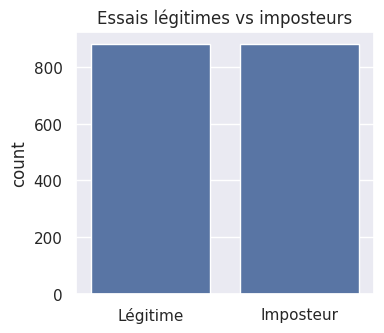

In [6]:
effectifs = df["type"].value_counts()
display(effectifs.rename("effectif").to_frame())
ratio = effectifs.min() / effectifs.max()
print(f"Rapport classe minoritaire / majoritaire = {ratio:.2f}")
if ratio >= 0.9:
    print("-> Classes équilibrées : pas de rééquilibrage nécessaire.")
else:
    print("-> Classes déséquilibrées : un rééquilibrage serait à envisager.")

plt.figure(figsize=(4, 3.5))
sns.countplot(data=df, x="type")
plt.title("Essais légitimes vs imposteurs"); plt.xlabel("")
plt.tight_layout(); plt.show()

### Distributions et corrélations

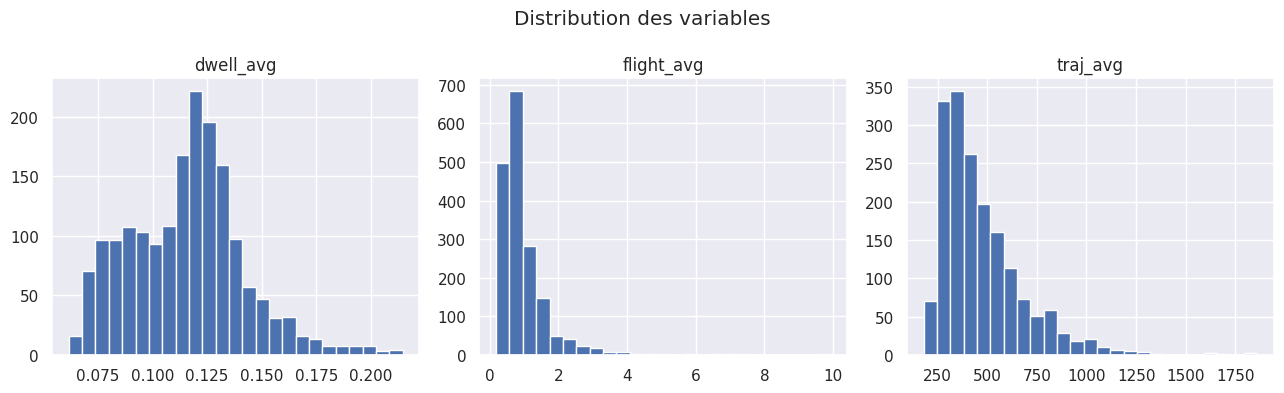

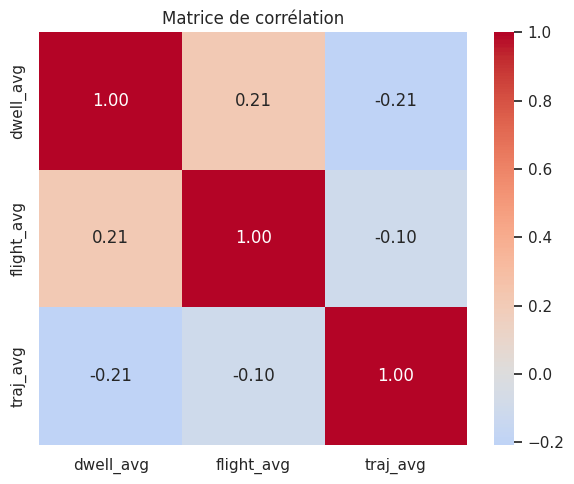

In [7]:
df[features].hist(figsize=(13, 4), bins=25, layout=(1, len(features)))
plt.suptitle("Distribution des variables")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Matrice de corrélation")
plt.tight_layout(); plt.show()

## 2. Identifier les caractéristiques liées au comportement de l'utilisateur
### Variables retenues et justification du choix de chacune
Le dataset ne fournit que trois variables,
- **Clavier :** `dwell_avg` (durée de maintien d'une touche) et `flight_avg` (temps entre deux frappes) ;
- **Souris :** `traj_avg` (trajectoire moyenne du pointeur).

Le nombre de variables étant très faible, **on les retient toutes** : en écarter une ferait perdre de l'information. On vérifie seulement qu'elles ne sont pas redondantes (corrélation faible entre elles).

## 3. Construire un profil comportemental normal pour chaque utilisateur

Le **profil normal** d'un utilisateur est la moyenne et l'écart-type de ses essais légitimes sur les variables retenues.

Profil normal des 5 premiers utilisateurs :


dwell_avg        flight_avg        traj_avg         
             mean    std       mean    std     mean      std
user_id                                                     
1           0.091  0.004      0.362  0.039  605.566   69.413
2           0.078  0.003      0.566  0.138  753.537  219.404
3           0.108  0.010      0.936  0.273  470.403  150.023
4           0.074  0.003      0.646  0.132  597.317  132.542
5           0.134  0.003      0.921  0.108  313.592   40.234

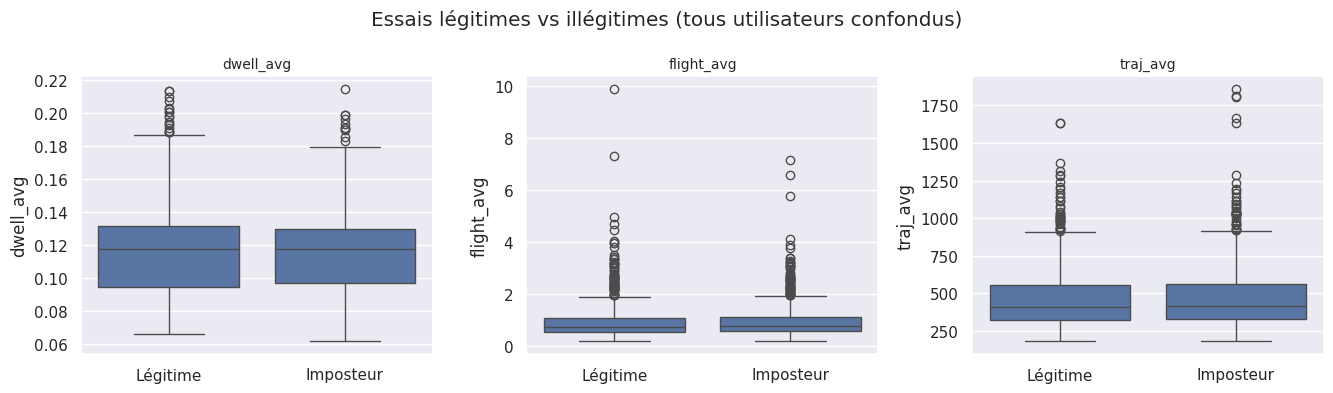

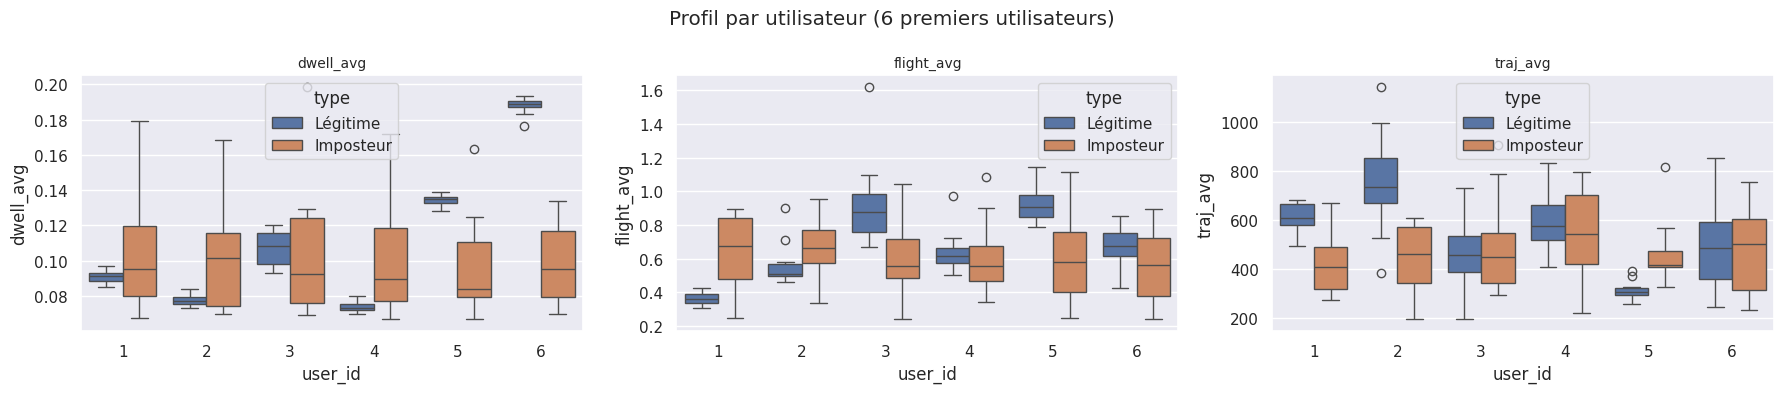

In [10]:
legitimes = df[df["label"] == 1]

profil = legitimes.groupby("user_id")[SELECTED].agg(["mean", "std"]).round(3)
print("Profil normal des 5 premiers utilisateurs :")
display(profil.head())

# Comparaison globale légitimes / imposteurs
fig, axes = plt.subplots(1, len(SELECTED), figsize=(4.5 * len(SELECTED), 4), squeeze=False)
for i in range(len(SELECTED)):
    sns.boxplot(data=df, x="type", y=SELECTED[i], ax=axes[0][i])
    axes[0][i].set_title(SELECTED[i], fontsize=10); axes[0][i].set_xlabel("")
plt.suptitle("Essais légitimes vs illégitimes (tous utilisateurs confondus)")
plt.tight_layout(); plt.show()

# Comparaison pour 6 utilisateurs : le profil est propre à chaque utilisateur
six = sorted(df["user_id"].unique())[:6]
fig, axes = plt.subplots(1, len(SELECTED), figsize=(6 * len(SELECTED), 4), squeeze=False)
for i in range(len(SELECTED)):
    sns.boxplot(data=df[df["user_id"].isin(six)], x="user_id", y=SELECTED[i], hue="type", ax=axes[0][i])
    axes[0][i].set_title(SELECTED[i], fontsize=10)
plt.suptitle("Profil par utilisateur (6 premiers utilisateurs)")
plt.tight_layout(); plt.show()

## 4. Préparer les données d'apprentissage et de test

Pour **chaque utilisateur** :
- **Apprentissage (70 %)** : 70 % de ses essais légitimes (7 essais), sans aucun imposteur.
- **Test (30 %)** : ses 3 autres essais légitimes + ses 10 essais illégitimes.
- Les variables retenues sont normalisées avec `StandardScaler`, dont les paramètres sont calculés **uniquement sur l'apprentissage** (pas de fuite d'information vers le test).

**Paramètres :** `TEST_SIZE = 0.3`, `random_state = 42`.

In [11]:
TEST_SIZE = 0.3

splits = {}      # pour chaque utilisateur : (X_train, X_test, y_test)
for uid, d in df.groupby("user_id"):
    legit = d[d["label"] == 1]
    imposteurs = d[d["label"] == 0]
    legit_train, legit_test = train_test_split(legit, test_size=TEST_SIZE, random_state=SEED)

    scaler = StandardScaler()
    scaler.fit(legit_train[SELECTED])

    test = pd.concat([legit_test, imposteurs])
    X_train = scaler.transform(legit_train[SELECTED])
    X_test = scaler.transform(test[SELECTED])
    splits[uid] = (X_train, X_test, test["label"].values)

uid0 = list(splits.keys())[0]
X_train, X_test, y_test = splits[uid0]
print("Utilisateurs :", len(splits))
print(f"Exemple (utilisateur {uid0}) -> apprentissage : {X_train.shape} | test : {X_test.shape} "
      f"({(y_test == 1).sum()} légitimes + {(y_test == 0).sum()} imposteurs)")

Utilisateurs : 88
Exemple (utilisateur 1) -> apprentissage : (7, 3) | test : (13, 3) (3 légitimes + 10 imposteurs)


## 5. Entraîner le modèle One-Class SVM

Un modèle par utilisateur, entraîné **uniquement sur ses essais légitimes** : il apprend une frontière autour du comportement normal.

| Paramètre | Valeur | Rôle |
|---|---|---|
| `kernel` | `rbf` | frontière courbe autour du comportement normal |
| `nu` | 0.1 | borne supérieure de la part d'essais d'apprentissage hors frontière (≈ 10 %) ; plus `nu` est grand, plus la frontière est serrée |
| `gamma` | `scale` | souplesse de la frontière, calculée automatiquement |

In [12]:
OCSVM_PARAMS = dict(kernel="rbf", nu=0.1, gamma="scale")

models_ocsvm = {}
for uid in splits:
    X_train = splits[uid][0]
    modele = OneClassSVM(**OCSVM_PARAMS)
    modele.fit(X_train)
    models_ocsvm[uid] = modele

print("Paramètres :", OCSVM_PARAMS, "| modèles entraînés :", len(models_ocsvm))

Paramètres : {'kernel': 'rbf', 'nu': 0.1, 'gamma': 'scale'} | modèles entraînés : 88


## 6. Entraîner le deuxième modèle : Isolation Forest

**Pourquoi ce choix ?** L'Isolation Forest est un détecteur d'anomalies non supervisé, d'un principe très différent du SVM : il isole chaque essai avec des coupes aléatoires dans plusieurs arbres. Un essai atypique est isolé en peu de coupes (score bas), un essai typique en demande beaucoup (score haut). Comme le SVM, il apprend uniquement sur les essais légitimes ; le seuil de décision par défaut est 0.

| Paramètre | Valeur | Rôle |
|---|---|---|
| `n_estimators` | 100 | nombre d'arbres |
| `max_samples` | `auto` | échantillon par arbre : min(256, nombre d'essais) = 7 ici |
| `contamination` | 0.1 | ≈ 10 % des essais d'apprentissage jugés anormaux (cohérent avec `nu`) |
| `random_state` | 42 | reproductibilité |

In [13]:
IF_PARAMS = dict(n_estimators=100, max_samples="auto", contamination=0.1, random_state=SEED)

models_if = {}
for uid in splits:
    X_train = splits[uid][0]
    modele = IsolationForest(**IF_PARAMS)
    modele.fit(X_train)
    models_if[uid] = modele

print("Paramètres :", IF_PARAMS, "| modèles entraînés :", len(models_if))

Paramètres : {'n_estimators': 100, 'max_samples': 'auto', 'contamination': 0.1, 'random_state': 42} | modèles entraînés : 88


## 7. Simuler des tentatives d'authentification normales et anormales

Chaque essai de test est une **tentative** : normale (légitime) ou anormale (imposteur). Le modèle donne un **score** : plus il est élevé, plus l'essai ressemble au profil normal.
**Score ≥ 0 : accepté ; score < 0 : rejeté.**

In [14]:
lignes = []
for nom, models in [(MODELS[0], models_ocsvm), (MODELS[1], models_if)]:
    for uid in models:
        X_test = splits[uid][1]
        y_test = splits[uid][2]
        scores_test = models[uid].decision_function(X_test)
        for i in range(len(y_test)):
            if y_test[i] == 1:
                type_tentative = "Normale"
            else:
                type_tentative = "Imposteur"
            lignes.append({"modele": nom, "user_id": uid, "tentative": type_tentative,
                           "y_true": int(y_test[i]), "score": float(scores_test[i])})

attempts = pd.DataFrame(lignes)
attempts["y_pred"] = (attempts["score"] >= 0).astype(int)      # 1 = accepté, 0 = rejeté

print("Tentatives simulées :", len(attempts))
display(attempts.groupby("modele").head(5).round(3))

Tentatives simulées : 2288


,modele,user_id,tentative,y_true,score,y_pred
0,One-Class SVM,1,Normale,1,-0.000,0
1,One-Class SVM,1,Normale,1,-0.063,0
2,One-Class SVM,1,Normale,1,0.025,1
3,One-Class SVM,1,Imposteur,0,-0.203,0
4,One-Class SVM,1,Imposteur,0,-0.211,0
1144,Isolation Forest,1,Normale,1,0.033,1
1145,Isolation Forest,1,Normale,1,0.016,1
1146,Isolation Forest,1,Normale,1,0.065,1
1147,Isolation Forest,1,Imposteur,0,-0.025,0
1148,Isolation Forest,1,Imposteur,0,-0.065,0


## 8. Identifier les comportements correspondant à un imposteur

Un imposteur est **détecté** si son essai est rejeté (score < 0). Ceux qui passent sont les **fausses acceptations**.

décision,Accepté (faux),Rejeté (correct)
modele,,
Isolation Forest,480,400
One-Class SVM,22,858


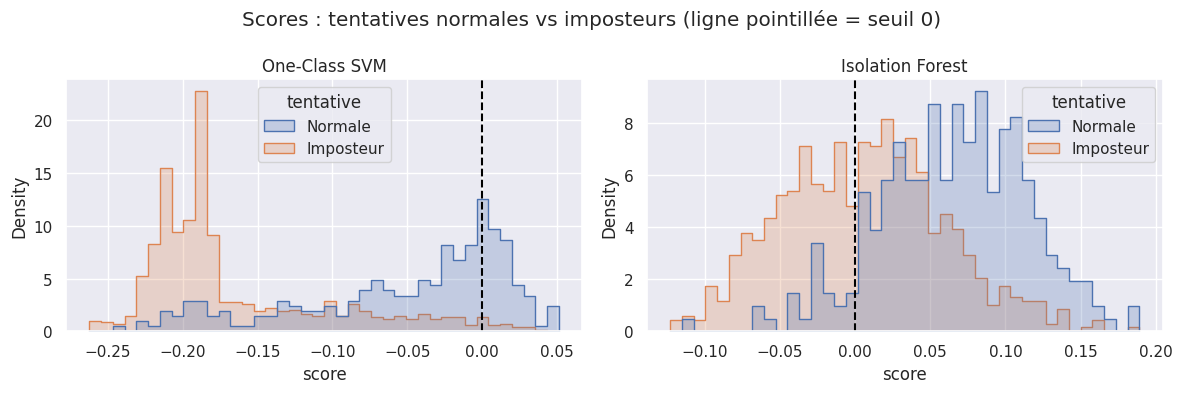

One-Class SVM : 5 utilisateurs avec le plus d'imposteurs acceptés (sur 10) :
{14: 4, 16: 2, 44: 2, 49: 2, 33: 1}
Isolation Forest : 5 utilisateurs avec le plus d'imposteurs acceptés (sur 10) :
{63: 10, 64: 10, 68: 10, 66: 10, 82: 10}

Écart moyen au profil de l'utilisateur (en écarts-types), imposteurs du One-Class SVM :


,dwell_avg,flight_avg,traj_avg
décision,,,
Accepté,-0.14,-0.03,-0.42
Rejeté,1.10,1.00,1.02


In [15]:
imposteurs = attempts[attempts["y_true"] == 0].copy()
imposteurs["décision"] = imposteurs["y_pred"].map({1: "Accepté (faux)", 0: "Rejeté (correct)"})
display(pd.crosstab(imposteurs["modele"], imposteurs["décision"]))

# Distribution des scores
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i in range(2):
    sub = attempts[attempts["modele"] == MODELS[i]]
    sns.histplot(data=sub, x="score", hue="tentative", bins=40, stat="density",
                 common_norm=False, element="step", ax=axes[i])
    axes[i].axvline(0, color="black", linestyle="--")
    axes[i].set_title(MODELS[i])
plt.suptitle("Scores : tentatives normales vs imposteurs (ligne pointillée = seuil 0)")
plt.tight_layout(); plt.show()

# Utilisateurs les plus vulnérables (imposteurs acceptés)
for nom in MODELS:
    sub = imposteurs[imposteurs["modele"] == nom]
    par_user = sub.groupby("user_id")["y_pred"].sum().sort_values(ascending=False)
    print(f"{nom} : 5 utilisateurs avec le plus d'imposteurs acceptés (sur 10) :")
    print(par_user.head(5).to_dict())

# Comportement moyen des imposteurs acceptés / rejetés (sur le modèle One-Class SVM), en unités normalisées
X_imp = []
dec = []
for uid in models_ocsvm:
    X_test = splits[uid][1]
    y_test = splits[uid][2]
    pred = models_ocsvm[uid].predict(X_test[y_test == 0])
    X_imp.append(X_test[y_test == 0])
    dec.extend(list(pred))
X_imp = pd.DataFrame(np.vstack(X_imp), columns=SELECTED)
X_imp["décision"] = ["Accepté" if p == 1 else "Rejeté" for p in dec]
print("\nÉcart moyen au profil de l'utilisateur (en écarts-types), imposteurs du One-Class SVM :")
display(X_imp.groupby("décision")[SELECTED].mean().round(2))

## 9. Évaluer les faux rejets et les fausses acceptations

- **FRR** (taux de faux rejets) : part des essais **légitimes rejetés** (gêne pour l'utilisateur).
- **FAR** (taux de fausses acceptations) : part des **imposteurs acceptés** (risque de sécurité).
- **HTER** = (FAR + FRR) / 2.

In [16]:
def metriques(a, seuil=0.0):
    accepte = a["score"] >= seuil
    legit = a["y_true"] == 1
    frr = 1 - accepte[legit].mean()
    far = accepte[~legit].mean()
    accuracy = (accepte == legit).mean()
    return {"Accuracy": accuracy, "FAR": far, "FRR": frr, "HTER": (far + frr) / 2}

lignes = {}
for nom in MODELS:
    lignes[nom] = metriques(attempts[attempts["modele"] == nom])
resultats = pd.DataFrame(lignes).T.round(4)
print("Résultats au seuil par défaut (0) :")
display(resultats)

Résultats au seuil par défaut (0) :


,Accuracy,FAR,FRR,HTER
One-Class SVM,0.8103,0.0250,0.7386,0.3818
Isolation Forest,0.5612,0.5455,0.0833,0.3144


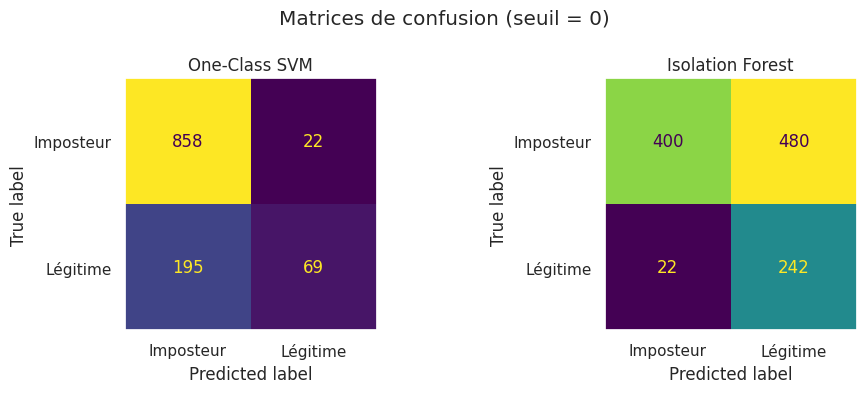

One-Class SVM : légitimes acceptés = 69, faux rejets = 195, fausses acceptations = 22, imposteurs rejetés = 858
Isolation Forest : légitimes acceptés = 242, faux rejets = 22, fausses acceptations = 480, imposteurs rejetés = 400


In [17]:
# Matrices de confusion (lignes = réalité, colonnes = décision)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i in range(2):
    sub = attempts[attempts["modele"] == MODELS[i]]
    ConfusionMatrixDisplay.from_predictions(sub["y_true"], sub["y_pred"], labels=[0, 1],
                                            display_labels=["Imposteur", "Légitime"], ax=axes[i], colorbar=False)
    axes[i].set_title(MODELS[i]); axes[i].grid(False)
plt.suptitle("Matrices de confusion (seuil = 0)")
plt.tight_layout(); plt.show()

for nom in MODELS:
    sub = attempts[attempts["modele"] == nom]
    vp = ((sub["y_true"] == 1) & (sub["y_pred"] == 1)).sum()   # légitimes acceptés
    fn = ((sub["y_true"] == 1) & (sub["y_pred"] == 0)).sum()   # légitimes rejetés (faux rejets)
    fp = ((sub["y_true"] == 0) & (sub["y_pred"] == 1)).sum()   # imposteurs acceptés (fausses acceptations)
    vn = ((sub["y_true"] == 0) & (sub["y_pred"] == 0)).sum()   # imposteurs rejetés
    print(f"{nom} : légitimes acceptés = {vp}, faux rejets = {fn}, fausses acceptations = {fp}, imposteurs rejetés = {vn}")

## 10. Comparer les performances des deux modèles

Deux mesures **indépendantes du seuil** :
- l'**AUC** (1 = séparation parfaite, 0.5 = hasard) ;
- l'**EER** (erreur au point où FAR = FRR ; plus bas = mieux).

,Accuracy,FAR,FRR,HTER,AUC,EER
Modèle,,,,,,
One-Class SVM,0.8103,0.0250,0.7386,0.3818,0.8692,0.1968
Isolation Forest,0.5612,0.5455,0.0833,0.3144,0.7954,0.2752


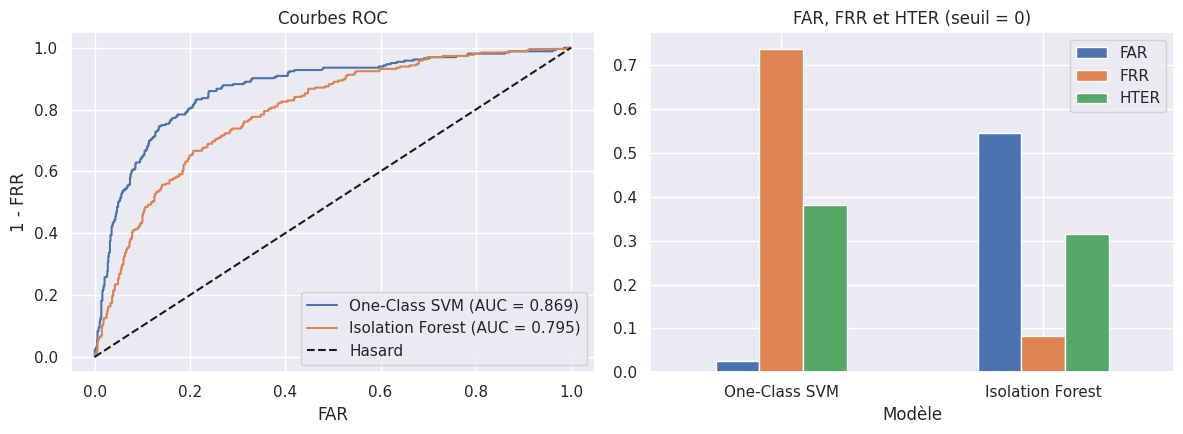

In [18]:
def calcul_eer(y_true, scores):
    far, tpr, seuils = roc_curve(y_true, scores)      # far = fausses acceptations ; 1 - tpr = faux rejets
    frr = 1 - tpr
    i = np.nanargmin(np.abs(frr - far))
    return (far[i] + frr[i]) / 2, seuils[i]

lignes = []
eer_seuil = {}
for nom in MODELS:
    sub = attempts[attempts["modele"] == nom]
    valeur_eer, seuil_eer = calcul_eer(sub["y_true"], sub["score"])
    eer_seuil[nom] = seuil_eer
    ligne = metriques(sub)
    ligne["Modèle"] = nom
    ligne["AUC"] = roc_auc_score(sub["y_true"], sub["score"])
    ligne["EER"] = valeur_eer
    lignes.append(ligne)
comparaison = pd.DataFrame(lignes).set_index("Modèle")
comparaison = comparaison[["Accuracy", "FAR", "FRR", "HTER", "AUC", "EER"]].round(4)
display(comparaison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nom in MODELS:
    sub = attempts[attempts["modele"] == nom]
    far, tpr, _ = roc_curve(sub["y_true"], sub["score"])
    auc = roc_auc_score(sub["y_true"], sub["score"])
    axes[0].plot(far, tpr, label=f"{nom} (AUC = {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Hasard")
axes[0].set_xlabel("FAR"); axes[0].set_ylabel("1 - FRR"); axes[0].set_title("Courbes ROC"); axes[0].legend()

comparaison[["FAR", "FRR", "HTER"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("FAR, FRR et HTER (seuil = 0)"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 11. Analyser l'influence du seuil de décision

Un essai est **accepté** si `score ≥ seuil`. Un seuil plus **haut** est plus strict (FAR ↓, FRR ↑) ; un seuil plus **bas** est plus permissif (FAR ↑, FRR ↓).

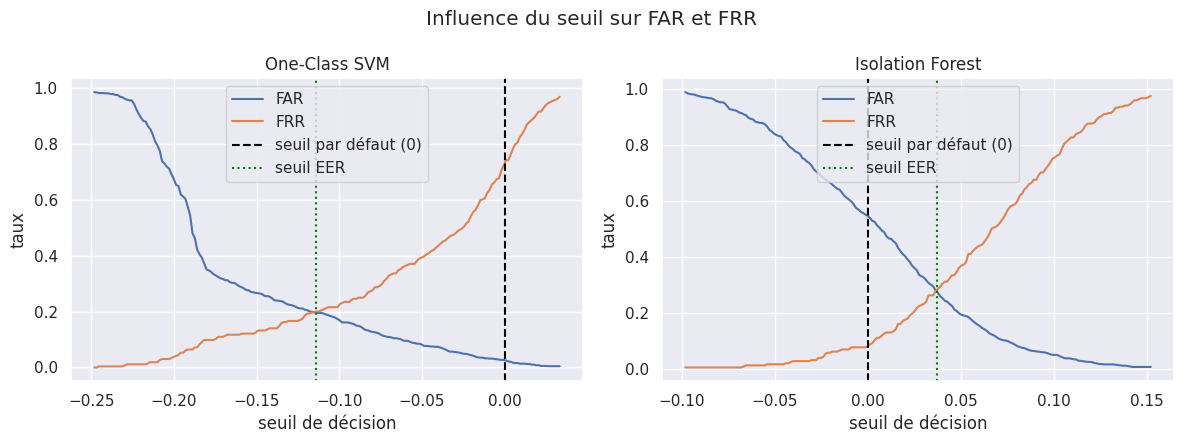

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for i in range(2):
    nom = MODELS[i]
    a = attempts[attempts["modele"] == nom]
    seuils = np.linspace(a["score"].quantile(0.01), a["score"].quantile(0.99), 200)
    far_liste = [metriques(a, t)["FAR"] for t in seuils]
    frr_liste = [metriques(a, t)["FRR"] for t in seuils]
    axes[i].plot(seuils, far_liste, label="FAR")
    axes[i].plot(seuils, frr_liste, label="FRR")
    axes[i].axvline(0, color="black", linestyle="--", label="seuil par défaut (0)")
    axes[i].axvline(eer_seuil[nom], color="green", linestyle=":", label="seuil EER")
    axes[i].set_xlabel("seuil de décision"); axes[i].set_ylabel("taux"); axes[i].set_title(nom); axes[i].legend()
plt.suptitle("Influence du seuil sur FAR et FRR")
plt.tight_layout(); plt.show()

In [20]:
# Tableau : FAR / FRR / HTER pour quelques seuils (centrés autour du seuil par défaut)
for nom in MODELS:
    a = attempts[attempts["modele"] == nom]
    ecart = a["score"].std()
    lignes = []
    for t in [-1, -0.5, 0, 0.5, 1]:
        seuil = t * ecart * 0.5
        m = metriques(a, seuil)
        lignes.append({"seuil": round(seuil, 3), "FAR": m["FAR"], "FRR": m["FRR"], "HTER": m["HTER"]})
    print(nom)
    display(pd.DataFrame(lignes).round(3))

# Seuil à choisir pour limiter les fausses acceptations à 5 %
for nom in MODELS:
    a = attempts[attempts["modele"] == nom]
    seuil_5 = a[a["y_true"] == 0]["score"].quantile(0.95)
    m = metriques(a, seuil_5)
    print(f"{nom} : pour FAR = 5 %, seuil = {seuil_5:.3f} -> FRR = {m['FRR']:.3f}")

One-Class SVM


,seuil,FAR,FRR,HTER
0,-0.04,0.074,0.436,0.255
1,-0.02,0.043,0.545,0.294
2,0.00,0.025,0.739,0.382
3,0.02,0.008,0.917,0.462
4,0.04,0.000,0.981,0.491


Isolation Forest


,seuil,FAR,FRR,HTER
0,-0.029,0.711,0.030,0.371
1,-0.015,0.634,0.068,0.351
2,0.000,0.545,0.083,0.314
3,0.015,0.450,0.133,0.291
4,0.029,0.328,0.227,0.278


One-Class SVM : pour FAR = 5 %, seuil = -0.026 -> FRR = 0.500
Isolation Forest : pour FAR = 5 %, seuil = 0.098 -> FRR = 0.746


## 12. Présentation et analyse des résultats expérimentaux

### 12.1 Résumé de l'environnement et des paramètres

In [21]:
print("Environnement : Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| graine =", SEED)
print("Données       :", df["user_id"].nunique(), "utilisateurs,", len(SELECTED), "variables retenues :", SELECTED)
print("Séparation    : par utilisateur, 70 % des essais légitimes pour l'apprentissage, test_size =", TEST_SIZE)
print("One-Class SVM :", OCSVM_PARAMS)
print("Isolation F.  :", IF_PARAMS)
print("Seuil par défaut : 0 (score >= 0 -> accepté)")

Environnement : Python 3.13.18 | scikit-learn 1.6.1 | graine = 42
Données       : 88 utilisateurs, 3 variables retenues : ['dwell_avg', 'flight_avg', 'traj_avg']
Séparation    : par utilisateur, 70 % des essais légitimes pour l'apprentissage, test_size = 0.3
One-Class SVM : {'kernel': 'rbf', 'nu': 0.1, 'gamma': 'scale'}
Isolation F.  : {'n_estimators': 100, 'max_samples': 'auto', 'contamination': 0.1, 'random_state': 42}
Seuil par défaut : 0 (score >= 0 -> accepté)


### 12.2 Résultats obtenus pour chaque modèle

In [22]:
for nom in MODELS:
    r = comparaison.loc[nom]
    print(f"{nom} : Accuracy = {r['Accuracy']:.3f} | FAR = {r['FAR']:.3f} | FRR = {r['FRR']:.3f} | "
          f"HTER = {r['HTER']:.3f} | AUC = {r['AUC']:.3f} | EER = {r['EER']:.3f}")

One-Class SVM : Accuracy = 0.810 | FAR = 0.025 | FRR = 0.739 | HTER = 0.382 | AUC = 0.869 | EER = 0.197
Isolation Forest : Accuracy = 0.561 | FAR = 0.545 | FRR = 0.083 | HTER = 0.314 | AUC = 0.795 | EER = 0.275


### 12.3 Interprétation et comparaison (générées à partir des résultats)

In [23]:
def niveau_auc(auc):
    if auc < 0.6:
        return "faible (proche du hasard)"
    if auc < 0.75:
        return "modérée"
    if auc < 0.9:
        return "bonne"
    return "très bonne"

for nom in MODELS:
    r = comparaison.loc[nom]
    print(f"* {nom} : AUC = {r['AUC']:.3f}, donc une capacité de séparation {niveau_auc(r['AUC'])} ;")
    print(f"    EER = {r['EER']:.3f} (erreur à FAR = FRR).")
    if r["FAR"] > r["FRR"]:
        print(f"    Au seuil 0, FAR ({r['FAR']:.3f}) > FRR ({r['FRR']:.3f}) : le modèle est plutôt permissif, "
              f"il accepte trop d'imposteurs (risque de sécurité).")
    else:
        print(f"    Au seuil 0, FRR ({r['FRR']:.3f}) >= FAR ({r['FAR']:.3f}) : le modèle est plutôt strict, "
              f"il rejette trop d'utilisateurs légitimes (gêne).")

meilleur = comparaison["AUC"].idxmax()
autre = [m for m in MODELS if m != meilleur][0]
ecart_auc = comparaison.loc[meilleur, "AUC"] - comparaison.loc[autre, "AUC"]
print()
print(f"Comparaison : {meilleur} obtient la meilleure AUC ({comparaison.loc[meilleur, 'AUC']:.3f} contre "
      f"{comparaison.loc[autre, 'AUC']:.3f}), soit un écart de {ecart_auc:.3f}.")
print(f"Son EER est de {comparaison.loc[meilleur, 'EER']:.3f} contre {comparaison.loc[autre, 'EER']:.3f} pour {autre}.")
if ecart_auc < 0.02:
    print("L'écart est très faible : les deux modèles ont des performances pratiquement équivalentes.")

* One-Class SVM : AUC = 0.869, donc une capacité de séparation bonne ;
    EER = 0.197 (erreur à FAR = FRR).
    Au seuil 0, FRR (0.739) >= FAR (0.025) : le modèle est plutôt strict, il rejette trop d'utilisateurs légitimes (gêne).
* Isolation Forest : AUC = 0.795, donc une capacité de séparation bonne ;
    EER = 0.275 (erreur à FAR = FRR).
    Au seuil 0, FAR (0.545) > FRR (0.083) : le modèle est plutôt permissif, il accepte trop d'imposteurs (risque de sécurité).

Comparaison : One-Class SVM obtient la meilleure AUC (0.869 contre 0.795), soit un écart de 0.074.
Son EER est de 0.197 contre 0.275 pour Isolation Forest.


### 12.4 Discussion et observations

**Variables et données.**
- Le jeu de données ne fournit que trois variables agrégées (moyennes par essai) : `dwell_avg` et `flight_avg` pour le clavier, `traj_avg` pour la souris. Prises tous utilisateurs confondus, leurs moyennes sont presque identiques entre essais légitimes et imposteurs (par exemple 0.116 contre 0.115 pour `dwell_avg`). Cela limite la séparation possible, quel que soit le modèle.
- Chaque utilisateur a un comportement régulier et personnel : ce qui est normal pour l'un est atypique pour l'autre. C'est pourquoi un modèle par utilisateur est pertinent.
- Les trois variables sont peu corrélées entre elles (corrélation maximale d'environ 0.2) : elles sont complémentaires et ont toutes été conservées.

**Taille des données d'apprentissage.**
- Chaque modèle n'est entraîné que sur 7 essais légitimes. C'est très peu : la frontière apprise est instable et les résultats dépendent du découpage aléatoire. Les valeurs de FAR et FRR par utilisateur sont donc bruitées, même si la moyenne sur les 88 utilisateurs est plus stable.

**Comparaison des deux modèles.**
- Le **One-Class SVM** est le meilleur : AUC = 0.869 contre 0.795, et EER = 0.197 contre 0.275. Sa frontière lisse (noyau RBF) convient bien aux petits échantillons.
- L'**Isolation Forest** est moins bon : avec 7 observations par arbre, les arbres sont très peu profonds et le score est grossier.
- Avec le seuil par défaut (0), les deux modèles sont mal calibrés, dans des sens opposés : le SVM est trop strict (FRR = 0.74, FAR = 0.03) et l'Isolation Forest trop permissif (FAR = 0.55, FRR = 0.08). Les mesures indépendantes du seuil (AUC et EER) donnent donc la comparaison la plus fiable.

**Influence du seuil.**
- Le seuil règle le compromis entre sécurité (FAR) et confort (FRR) : l'augmenter réduit les imposteurs acceptés mais rejette davantage d'utilisateurs légitimes, et inversement.
- Le seuil par défaut (0) n'est pas optimal. Par exemple, pour le SVM, abaisser le seuil à −0.04 fait passer le HTER de 0.38 à 0.26.
- Le choix du seuil dépend de l'usage : un système bancaire privilégiera un FAR faible, une application grand public un FRR faible.

**Limites et perspectives.**
- Peu de variables, peu d'essais par utilisateur, un seul découpage apprentissage / test et des paramètres non optimisés (`nu`, `gamma`, `contamination`).
- Les seuils « EER » et « FAR = 5 % » sont calculés sur les données de test : ils sont illustratifs. Dans un vrai système, il faudrait les fixer sur des données de validation.
- Pistes d'amélioration : plus d'essais par utilisateur, optimisation des paramètres, plusieurs découpages pour mesurer la stabilité, et un seuil propre à chaque utilisateur.

In [24]:
meilleur = comparaison["AUC"].idxmax()
print(f"Sur {df['user_id'].nunique()} utilisateurs et {len(SELECTED)} variables comportementales, le meilleur modèle est "
      f"{meilleur} (AUC = {comparaison.loc[meilleur, 'AUC']:.3f}, EER = {comparaison.loc[meilleur, 'EER']:.3f}).")
print("Le seuil de décision permet d'ajuster le compromis entre fausses acceptations et faux rejets selon le niveau de sécurité voulu.")

Sur 88 utilisateurs et 3 variables comportementales, le meilleur modèle est One-Class SVM (AUC = 0.869, EER = 0.197).
Le seuil de décision permet d'ajuster le compromis entre fausses acceptations et faux rejets selon le niveau de sécurité voulu.
